In [2]:
from antares_devkit.models import BaseFilter
from antares_devkit.models import DevKitLocus
from antares_client import search
import numpy as np
import matplotlib.pyplot as plt
from astropy.time import Time
import pandas as pd
import math
from astropy.coordinates import Angle, SkyCoord
import astropy.units as u
import time
import warnings
import itertools

In [150]:
#extract data from lsst alert
def lsst_alert(alert):
    obs_date = float(alert.properties['lsst_diaSource_midpointMjdTai'])
    oid_mag = float(-2.5*np.log10(alert.properties['lsst_diaSource_scienceFlux']) + 31.4)
    temp_mag = float(-2.5*np.log10(alert.properties['lsst_diaSource_templateFlux']) + 31.4)
    diff_mag = float(temp_mag - oid_mag)
    
    bandpass = alert.properties['lsst_diaSource_band']
    band = 'lsst_' + str(bandpass)

    if alert.properties['lsst_diaSource_isNegative'] == True:
        pos_or_neg = -1
    else:
        pos_or_neg = 1
        
    return {band: [obs_date, oid_mag, temp_mag, diff_mag, pos_or_neg]}

def lsst_quality(alert):
    quality = True
    quality &= alert.properties['lsst_diaSource_reliability'] >= 0.6
    quality &= alert.properties['lsst_diaSource_psfFlux_flag'] == False
    quality &= alert.properties['lsst_diaSource_centroid_flag'] == False
    quality &= alert.properties['lsst_diaSource_shape_flag'] == False
    quality &= alert.properties['lsst_diaSource_isDipole'] == False
    quality &= alert.properties['lsst_diaSource_pixelFlags_saturated'] == False
    quality &= alert.properties['lsst_diaSource_pixelFlags_edge'] == False
    quality &= alert.properties['lsst_diaSource_pixelFlags_cr'] == False
    quality &= alert.properties['lsst_diaSource_pixelFlags_streak'] == False
    quality &= alert.properties['lsst_diaSource_scienceFlux'] >= 0
    quality &= alert.properties['lsst_diaSource_templateFlux'] >= 0

    if 'lsst_diaSource_ssObjectId' in alert.properties:
        quality &= alert.properties['lsst_diaSource_ssObjectId'] in (0, None, "0")
    return quality

#extract data from ztf alert
#uses formula from 260609 6/15 markdown cell
def ztf_alert(alert):
    bands = ['x', 'g', 'R', 'i']
    
    band_id = alert.properties['ztf_fid']
    obs_date = float(alert.properties['ant_mjd'])
    ant_mag = alert.properties['ant_mag']
    temp_mag = alert.properties['ztf_magnr']
    diff_img_mag = alert.properties['ztf_magpsf']
    
    if alert.properties['ztf_isdiffpos'] == 'f' or alert.properties['ztf_isdiffpos'] == 0:
        diff_mag = -2.5* np.log10(1 - 10.**(0.4*(temp_mag - diff_img_mag)))
        pos_or_neg = -1
    else:
        diff_mag = -2.5* np.log10(10.**(0.4*(temp_mag - diff_img_mag)) + 1)
        pos_or_neg = 1

    oid_mag = diff_mag + temp_mag
    band = 'ztf_' + str(bands[band_id])
    return {band: [obs_date, oid_mag, temp_mag, diff_mag, pos_or_neg]}

#checks ztf alert for good quality
def ztf_quality(alert):
    quality = True
    quality &= alert.properties['ztf_rb'] >= 0.65
    quality &= alert.properties['ztf_nbad'] == 0
    quality &= alert.properties['ztf_fwhm'] <= 5
    quality &= alert.properties['ztf_elong'] <= 1.2
    quality &= abs(alert.properties['ztf_magdiff']) <= 0.1
    return quality

#unpacks all alerts (that pass a quality test)
def oid_get_info(alerts, latest_mjd, day_lim = DAY_LIM):
    oid = {'lsst_g': 0, 'lsst_r': 0, 'lsst_i': 0, 'lsst_z': 0, 'lsst_u': 0, 'lsst_y': 0, 
               'ztf_g': 0, 'ztf_R': 0, 'ztf_i': 0}

    #snr check
    if alerts[-1].properties['ant_survey'] == 4:
        if alerts[-1].properties['lsst_diaSource_snr'] < 8:
            return 'snr too low'
        elif lsst_quality(alerts[-1]) == False:
            return 'lsst alert quality fail'
        else:  # check if bright
            trig_alert = lsst_alert(alerts[-1])
            band = [*trig_alert][0]
            if trig_alert[band][1] > 21:
                return 'triggered alert too dim'
    elif alerts[-1].properties['ant_survey'] == 1:
        if (1.0857/alerts[-1].properties['ztf_sigmapsf']) < 8:
            return 'snr too low'

    for alert in alerts:
        #check mjd
        if alert.properties['ant_mjd'] < (math.floor(latest_mjd) - day_lim):
            continue

        # quality check
        if alert.properties['ant_survey'] == 4:
            lsst_pass = lsst_quality(alert)
            if lsst_pass == True:
                comp = lsst_alert(alert)
            else:
                continue
        elif alert.properties['ant_survey'] == 1:
            ztf_pass = ztf_quality(alert)
            if ztf_pass == True:
                comp = ztf_alert(alert)
            else:
                continue
        else:
            continue
            
        band = [*comp][0]
        #put quality data together organized by band
        if isinstance(oid[band], pd.DataFrame) == 0:
            oid_df = pd.DataFrame([comp[band]], columns = ['mjd', 'oid_mag', 'template_mag', 'diff_mag', 'pos/neg'])
            oid[band] = oid_df
            continue
        else:
            data_df = pd.DataFrame([comp[band]], columns = ['mjd', 'oid_mag', 'template_mag', 'diff_mag', 'pos/neg'])
            current_data = oid[band]
            oid[band] = pd.concat([current_data, data_df]).drop_duplicates().reset_index(drop=True)

    #checking if any data passed
    fail = 0
    for band in oid:
        if isinstance(oid[band], pd.DataFrame) == False:
            fail += 1
    if fail == 9:
        return 'no recent data'
    else:
        return oid

def var_params(oid, coeff=COEFF):
    vp = {'lsst_g': 0, 'lsst_r': 0, 'lsst_i': 0, 'lsst_z': 0, 'lsst_u': 0, 'lsst_y': 0, 
               'ztf_g': 0, 'ztf_R': 0, 'ztf_i': 0}
    data_lim = 0
    for band in oid:
        if band == 'locus':
            continue
        if isinstance(oid[band], pd.DataFrame) == 0:
            data_lim += 1
            continue
        if len(oid[band]) < 3:
            data_lim += 1
            vp[band] = {'diff_mag':0, 'var':0, 'hyper_v':0, 'data':oid[band]}
        
        max_mjd_i = oid[band].mjd.idxmax()
        diff_mag = float(oid[band]['diff_mag'][max_mjd_i])
        var = np.var(oid[band]['oid_mag'])
        hv = float(np.sqrt(diff_mag ** 2 + (coeff * var) ** 2))
        vp[band] = {'diff_mag':diff_mag, 'var':var, 'hyper_v':hv, 'data':oid[band]}
        
    if data_lim == 9:
        return 0
    else: 
        return vp

def catalog_check(locus):
    flags = {'known_star': False, 'known_agn': False, 'known_galaxy': False, 'gaia_likely_star': False, 
                            'gaia_astro_star': False, 'ps1_pointlike': False}
    for cat in locus.catalog_objects:
        if cat == 'asassn_variable_catalog' or cat == 'asassn_variable_Catalog_v2_20190802' or cat == 'sdss_stars':
            flags['known_star'] = True
        if cat == 'veron_agn_qso' or cat == 'milliquas':
            flags['known_agn'] = True
        if cat == '2mass_xsc' or cat == 'nyu_valueadded_gals' or cat == 'sdss_gals' or cat == 'RC3':
            flags['known_galaxy'] = True
        if cat == 'gaia_dr3_gaia_source':
            if isinstance(locus.catalog_objects[cat][0]['classprob_dsc_combmod_star'], float) == 1 and locus.catalog_objects[cat][0]['classprob_dsc_combmod_star'] > 0.5:
                flags['gaia_likely_star'] = True
            if isinstance(locus.catalog_objects[cat][0]['parallax'], float) == 1:
                gdr3_check1 = (locus.catalog_objects[cat][0]['parallax'] + 0.017)/locus.catalog_objects[cat][0]['parallax_error']
                alpha = locus.catalog_objects[cat][0]['pmra']/locus.catalog_objects[cat][0]['pmra_error']
                beta = locus.catalog_objects[cat][0]['pmdec']/locus.catalog_objects[cat][0]['pmdec_error']
                gamma = locus.catalog_objects[cat][0]['pmra_pmdec_corr']
                gdr3_check2 = np.sqrt((alpha**2 + beta**2 -2*alpha*beta*gamma)/(1 - gamma**2))
                if gdr3_check1 > 5 or gdr3_check2 > 5:
                    flags['gaia_astro_star'] = True
        alert_temp = locus.alerts[-1].properties
        if alert_temp['ant_survey'] == 1 and ((alert_temp['ztf_sgscore1'] > 0.5 and alert_temp['ztf_distpsnr1'] < 1) or (alert_temp['ztf_sgscore2'] > 0.5 and alert_temp['ztf_distpsnr2'] < 1) or (alert_temp['ztf_sgscore3'] > 0.5 and alert_temp['ztf_distpsnr3'] < 1)):
            flags['ps1_pointlike'] = True
    return flags

def query_by_chunk(mjd_start, mjd_end, ra_min, ra_max, dec_min, dec_max,
                   faint_lim=FAINT_MAG_LIM, min_ndet=MIN_NDET, max_results=ANTARES_MAX_RETURN,
                   retries=3, wait=15):
    # set the query to fetch loci with alerts matching search criteria
    query = {
        "query": {
            "bool": {
                "filter": [
                    { "range": { "properties.newest_alert_observation_time": { "gte": mjd_start, "lte": mjd_end} } },
                    { "range": { "properties.brightest_alert_magnitude": {"lte": faint_lim} } },
                    { "range": { "ra": { "gte": ra_min, "lte": ra_max} } },
                    { "range": { "dec": { "gte": dec_min, "lte": dec_max} } }
                      ]
            }
        }
    }

    # sometimes the ANTARES server times out so try a few times
    # before giving up and returning an empty list (to avoid crashing the entire query)
    for attempt in range(retries):
        try:
            loci = list(search.search(query))
            if len(loci) >= max_results:
                warnings.warn(
                    f'Chunk MJD {mjd_start:.1f}–{mjd_end:.1f} hit the {max_results}-result max.'
                    f'— Reduce QUERY_DT or this window is incomplete.',
                    stacklevel=2
                )
            return get_ids(loci)
        except Exception as e:
            if attempt < retries - 1:
                print(f'  Chunk {mjd_start}–{mjd_end} failed (attempt {attempt+1}/{retries}): {e}.')
                time.sleep(wait)
            else:
                print(f'  Chunk {mjd_start}–{mjd_end} giving up after {retries} attempts.')
                return []

def get_ids(loci):
    # print(loci)
    loci_ids = []
    for locus in loci:
        loci_ids.append(locus.locus_id)
    return loci_ids

def get_target_info(oid, make_csv=False):
    
    if make_csv == False:
        return #dict
    else:
        #make csv file and return it
        a = 1
        
# def hyperv_pass(oid, coeff=COEFF, hyper_v_thresh):
#     for band in oid:
#         if band == 'locus':
#             continue
#         if isinstance(oid[band], pd.DataFrame) == 0:
#             continue
#         if len(oid[band]) < 3:
#             continue
        
#         max_mjd_i = oid[band].mjd.idxmax()
#         diff_mag = float(oid[band]['diff_mag'][max_mjd_i])
#         var = np.var(oid[band]['oid_mag'])
#         hv = float(np.sqrt(diff_mag ** 2 + (coeff * var) ** 2))

#         if hv >= hv_thresh
#             return 1
#     return 0


def lightcurve(alerts):
    lc = {'lsst_g': 0, 'lsst_r': 0, 'lsst_i': 0, 'lsst_z': 0, 'lsst_u': 0, 'lsst_y': 0, 
         'ztf_g': 0, 'ztf_R': 0, 'ztf_i': 0}
    
    for alert in alerts:
        if alert.properties['ant_survey'] == 4:
            # lsst_pass = lsst_quality(alert)
            # if lsst_pass == True:
            comp = lsst_alert(alert)
            # else:
            #     continue
        elif alert.properties['ant_survey'] == 1:
            # ztf_pass = ztf_quality(alert)
            # if ztf_pass == True:
            comp = ztf_alert(alert)
            # else:
            #     continue
        else:
            continue
        band = [*comp][0]
        here = {'mjd': comp[band][0], 'mag':comp[band][1], 'temp_mag':comp[band][2]}
        # here = pd.DataFrame([[band], [comp[band][0]], [comp[band][1]]], columns = ['band', 'mjd', 'mag'])
        if isinstance(lc[band], pd.DataFrame) == 0:
            lc[band] = pd.DataFrame(data=here, index=[0])
        else:
            h = pd.DataFrame(data=here, index=[-1])
            lc[band] = pd.concat([lc[band], h]).reset_index(drop=True)
    return lc

In [4]:
RA_MIN = 0.0
RA_MAX = 50.0
DEC_MIN = -50.0
DEC_MAX = 30.0
FAINT_MAG_LIM = 21
MIN_NDET = 3
ANTARES_MAX_RETURN = 10000
DAY_LIM = 60
t_now = Time.now().mjd
COEFF = 6

In [99]:
# a = query_by_chunk(t_now - 1, t_now)

61291 61290.958168104364


In [100]:
fail_stats = {}
stats_now = {'snr':0, 'recency':0, 'trig_a_quality':0, 'faint':0, 'data_limitted':0,'variable':0,'checked':0}

oid_sample = {}
ra_s = np.arange(0, 360, 10)
dec_s = np.arange(-90, 40, 10)
# ra_s = [0.0]
# dec_s = [0.0]

FAINT_MAG_LIM = 21.0
MIN_NDET = 3
ANTARES_MAX_RETURN = 10000
DAY_LIM = 30
t_now = Time.now().mjd

for ra, dec in list(itertools.product(ra_s, dec_s)):
    RA_MIN = float(ra)
    RA_MAX = float(RA_MIN + 10)
    DEC_MIN = float(dec)
    DEC_MAX = float(DEC_MIN + 10)
    
    loci_ids = query_by_chunk(t_now-1, t_now, RA_MIN, RA_MAX, DEC_MIN, DEC_MAX)
    print(f'({RA_MIN} - {RA_MAX}, {DEC_MIN} - {DEC_MAX}) : {len(loci_ids)}')
    
    for l_id in loci_ids:
        locus = search.get_by_id(l_id)
        oid_dv = locus.to_devkit()
        oid_locus = DevKitLocus.model_validate(oid_dv)
        
        oid_here = oid_get_info(oid_locus.alerts, oid_locus.properties['newest_alert_observation_time'])
    
        if isinstance(oid_here, str):
            if oid_here == 'snr too low':
                stats_now['snr'] += 1
            elif oid_here == 'no recent data':
                stats_now['recency'] += 1
            elif oid_here == 'lsst alert quality fail':
                stats_now['trig_a_quality'] += 1
            elif oid_here == 'triggered alert too dim':
                stats_now['faint'] += 1
        else:
            vp_here = var_params(oid_here)
            if isinstance(vp_here, str) == 1:
                stats_now['variable'] += 1
            elif isinstance(vp_here, dict) == 0:
                stats_now['data_limitted'] += 1
            else:
                flags = catalog_check(locus)
                oid_sample[oid_dv['id']] = vp_here
                oid_sample[oid_dv['id']]['flags'] = flags
    stats_now['checked'] += len(loci_ids)
fail_stats[math.floor(t_now)] = stats_now

(0.0 - 10.0, -90.0 - -80.0) : 0
(0.0 - 10.0, -80.0 - -70.0) : 0
(0.0 - 10.0, -70.0 - -60.0) : 0
(0.0 - 10.0, -60.0 - -50.0) : 0
(0.0 - 10.0, -50.0 - -40.0) : 0
(0.0 - 10.0, -40.0 - -30.0) : 0
(0.0 - 10.0, -30.0 - -20.0) : 0
(0.0 - 10.0, -20.0 - -10.0) : 0
(0.0 - 10.0, -10.0 - 0.0) : 0
(0.0 - 10.0, 0.0 - 10.0) : 0
(0.0 - 10.0, 10.0 - 20.0) : 18
(0.0 - 10.0, 20.0 - 30.0) : 5
(0.0 - 10.0, 30.0 - 40.0) : 0
(10.0 - 20.0, -90.0 - -80.0) : 0
(10.0 - 20.0, -80.0 - -70.0) : 0
(10.0 - 20.0, -70.0 - -60.0) : 0
(10.0 - 20.0, -60.0 - -50.0) : 0
(10.0 - 20.0, -50.0 - -40.0) : 0
(10.0 - 20.0, -40.0 - -30.0) : 0
(10.0 - 20.0, -30.0 - -20.0) : 0
(10.0 - 20.0, -20.0 - -10.0) : 0
(10.0 - 20.0, -10.0 - 0.0) : 0
(10.0 - 20.0, 0.0 - 10.0) : 0
(10.0 - 20.0, 10.0 - 20.0) : 3
(10.0 - 20.0, 20.0 - 30.0) : 0
(10.0 - 20.0, 30.0 - 40.0) : 0
(20.0 - 30.0, -90.0 - -80.0) : 0
(20.0 - 30.0, -80.0 - -70.0) : 0
(20.0 - 30.0, -70.0 - -60.0) : 0
(20.0 - 30.0, -60.0 - -50.0) : 0
(20.0 - 30.0, -50.0 - -40.0) : 0
(20.0 - 30.

KeyboardInterrupt: 

In [21]:
t_now = Time.now().mjd
t_now

np.float64(61290.690619823785)

In [26]:
snr_f_61289 = 0
recent_f_61289 = 0
lsst_q_f_61289 = 0
mag_f_61289 = 0
vp_dl_f_61289 = 0
variable_f_61289 = 0
checked_61289 = 0

oid_sample_61289 = {}
ra_s = np.arange(0, 360, 10)
dec_s = np.arange(-90, 45, 10)
# ra_s = [0.0]
# dec_s = [0.0]

FAINT_MAG_LIM = 21.0
MIN_NDET = 3
ANTARES_MAX_RETURN = 10000
DAY_LIM = 30
t_now = Time.now().mjd

for ra, dec in list(itertools.product(ra_s, dec_s)):
    RA_MIN = float(ra)
    RA_MAX = float(RA_MIN + 10)
    DEC_MIN = float(dec)
    DEC_MAX = float(DEC_MIN + 10)
    
    loci_ids = query_by_chunk(t_now-3, t_now, RA_MIN, RA_MAX, DEC_MIN, DEC_MAX)
    print(f'({RA_MIN} - {RA_MAX}, {DEC_MIN} - {DEC_MAX}) : {len(loci_ids)}')
    
    for l_id in loci_ids:
        locus = search.get_by_id(l_id)
        oid_dv = locus.to_devkit()
        oid_locus = DevKitLocus.model_validate(oid_dv)
        
        oid_here = oid_get_info(oid_locus.alerts, oid_locus.properties['newest_alert_observation_time'])
    
        if isinstance(oid_here, str):
            if oid_here == 'snr too low':
                snr_f_61289 += 1
            elif oid_here == 'no recent data':
                recent_f_61289 += 1
            elif oid_here == 'lsst alert quality fail':
                lsst_q_f_61289 += 1
            elif oid_here == 'triggered alert too dim':
                mag_f_61289 += 1
        else:
            vp_here = var_params(oid_here)
            if isinstance(vp_here, str) == 1:
                variable_f_61289 += 1
            elif isinstance(vp_here, dict) == 0:
                vp_dl_f_61289 += 1
            else:
                flags = catalog_check(locus)
                oid_sample_61289[oid_dv['id']] = vp_here
                oid_sample_61289[oid_dv['id']]['flags'] = flags
    checked_61289 += len(loci_ids)


(0.0 - 10.0, -90.0 - -80.0) : 0
(0.0 - 10.0, -80.0 - -70.0) : 0
(0.0 - 10.0, -70.0 - -60.0) : 0
(0.0 - 10.0, -60.0 - -50.0) : 0
(0.0 - 10.0, -50.0 - -40.0) : 0
(0.0 - 10.0, -40.0 - -30.0) : 0
(0.0 - 10.0, -30.0 - -20.0) : 312


/var/folders/ym/gbj1z46s0wg5zdmkkq0xpptr0000gs/T/ipykernel_7011/727274070.py:48: RuntimeWarning: invalid value encountered in log10
  diff_mag = -2.5* np.log10(1 - 10.**(0.4*(temp_mag - diff_img_mag)))


(0.0 - 10.0, -20.0 - -10.0) : 1049


/var/folders/ym/gbj1z46s0wg5zdmkkq0xpptr0000gs/T/ipykernel_7011/727274070.py:48: RuntimeWarning: invalid value encountered in log10
  diff_mag = -2.5* np.log10(1 - 10.**(0.4*(temp_mag - diff_img_mag)))


(0.0 - 10.0, -10.0 - 0.0) : 2001
(0.0 - 10.0, 0.0 - 10.0) : 2360


...

(270.0 - 280.0, -10.0 - 0.0) : 1733


/var/folders/ym/gbj1z46s0wg5zdmkkq0xpptr0000gs/T/ipykernel_7011/727274070.py:48: RuntimeWarning: invalid value encountered in log10
  diff_mag = -2.5* np.log10(1 - 10.**(0.4*(temp_mag - diff_img_mag)))
/var/folders/ym/gbj1z46s0wg5zdmkkq0xpptr0000gs/T/ipykernel_7011/727274070.py:48: RuntimeWarning: invalid value encountered in log10
  diff_mag = -2.5* np.log10(1 - 10.**(0.4*(temp_mag - diff_img_mag)))
/var/folders/ym/gbj1z46s0wg5zdmkkq0xpptr0000gs/T/ipykernel_7011/727274070.py:48: RuntimeWarning: invalid value encountered in log10
  diff_mag = -2.5* np.log10(1 - 10.**(0.4*(temp_mag - diff_img_mag)))
/var/folders/ym/gbj1z46s0wg5zdmkkq0xpptr0000gs/T/ipykernel_7011/727274070.py:48: RuntimeWarning: invalid value encountered in log10
  diff_mag = -2.5* np.log10(1 - 10.**(0.4*(temp_mag - diff_img_mag)))
/var/folders/ym/gbj1z46s0wg5zdmkkq0xpptr0000gs/T/ipykernel_7011/727274070.py:48: RuntimeWarning: invalid value encountered in log10
  diff_mag = -2.5* np.log10(1 - 10.**(0.4*(temp_mag - diff_i

(270.0 - 280.0, 0.0 - 10.0) : 1712


/var/folders/ym/gbj1z46s0wg5zdmkkq0xpptr0000gs/T/ipykernel_7011/727274070.py:48: RuntimeWarning: invalid value encountered in log10
  diff_mag = -2.5* np.log10(1 - 10.**(0.4*(temp_mag - diff_img_mag)))
/var/folders/ym/gbj1z46s0wg5zdmkkq0xpptr0000gs/T/ipykernel_7011/727274070.py:48: RuntimeWarning: invalid value encountered in log10
  diff_mag = -2.5* np.log10(1 - 10.**(0.4*(temp_mag - diff_img_mag)))
/var/folders/ym/gbj1z46s0wg5zdmkkq0xpptr0000gs/T/ipykernel_7011/727274070.py:48: RuntimeWarning: invalid value encountered in log10
  diff_mag = -2.5* np.log10(1 - 10.**(0.4*(temp_mag - diff_img_mag)))
/var/folders/ym/gbj1z46s0wg5zdmkkq0xpptr0000gs/T/ipykernel_7011/727274070.py:48: RuntimeWarning: invalid value encountered in log10
  diff_mag = -2.5* np.log10(1 - 10.**(0.4*(temp_mag - diff_img_mag)))
/var/folders/ym/gbj1z46s0wg5zdmkkq0xpptr0000gs/T/ipykernel_7011/727274070.py:48: RuntimeWarning: invalid value encountered in log10
  diff_mag = -2.5* np.log10(1 - 10.**(0.4*(temp_mag - diff_i

ReadTimeout: HTTPSConnectionPool(host='api.antares.noirlab.edu', port=443): Read timed out. (read timeout=60)

In [27]:
print(f'total: {checked_61289}, passed: {len(oid_sample_61289)} ({len(oid_sample_61289)*100/checked_61289})%\nfails from: snr {snr_f_61289}, recency {recent_f_61289}, brightness {mag_f_61289}, quality {lsst_q_f_61289}, data limitting {vp_dl_f_61289}')
# print(checked)

total: 47773, passed: 6729 (14.08536202457455)%
fails from: snr 15661, recency 8855, brightness 0, quality 0, data limitting 16717


In [68]:
oid_sample.keys()

dict_keys(['ANT2020ndhe6', 'ANT2018gw7nk', 'ANT2019ajzq', 'ANT2019iydy6', 'ANT2020ubt2y', 'ANT2020sswfy', 'ANT2019hosco', 'ANT20203y5bk', 'ANT2020tixqa', 'ANT2018gx22g', 'ANT2019an6pk', 'ANT2020ae457aq', 'ANT2018ghtcm', 'ANT2019cye6e', 'ANT2020tiwxw', 'ANT2018gwotm', 'ANT2018ghsfo', 'ANT2018gynms', 'ANT2020tix2g', 'ANT2018gxcyw', 'ANT2020sxses', 'ANT2020nqw72', 'ANT2026h29ubsu3chcs', 'ANT2018ibxcs', 'ANT2018gxck6', 'ANT2018gwge6', 'ANT2018h3kce', 'ANT2018gxyke', 'ANT2018g43t6', 'ANT2018gw2gc', 'ANT2019mu2qo', 'ANT2020ngfmq', 'ANT2020w7dyo', 'ANT2018fyxo2', 'ANT2018h4evy', 'ANT2020mwxtm', 'ANT2020stvce', 'ANT2018h4p7i', 'ANT2023q33bjrwn8n4x', 'ANT2020xqfru', 'ANT2018g5k2y', 'ANT2018gv5dw', 'ANT2018gyqc2', 'ANT2018g6bys', 'ANT2018gvxeq', 'ANT2019g4fka', 'ANT2018g6zb6', 'ANT2018g53e6', 'ANT2018h22ea', 'ANT2018gueis', 'ANT2018fyxr2', 'ANT2018gyf5a', 'ANT2020nbuxq', 'ANT2018hzysu', 'ANT2020swrqu', 'ANT2020rqpyi', 'ANT2018g43mc', 'ANT2019chhzk', 'ANT20227bo57dv0vmu0', 'ANT2018g5beu', 'ANT201

In [87]:
locus = search.get_by_id('ANT2018gxcyw')
for alert in locus.alerts:
    if alert.properties['ant_mjd'] >= 61269 and alert.properties['ant_mjd'] <= 61270:
        if alert.properties['ant_passband'] == 'R':
            a = alert.properties
            # print(alert.properties['ztf_fid'], alert.properties['ant_mjd'], alert.properties['ant_mag'], alert.properties['ztf_magnr'], alert.properties['ztf_magpsf'], alert.properties['ztf_isdiffpos'])
            t_m = alert.properties['ztf_magnr']
            di_m = alert.properties['ztf_magpsf']
            print(0.4*(t_m - di_m))

0.002008056640625


In [97]:
t_m = a['ztf_magnr']
di_m = a['ztf_magpsf']
print(f'template_mag: {t_m}, difference_img_mag: {di_m}, difference: {t_m-di_m}\nmath: {0.4*(t_m-di_m), 10**(0.4*(t_m-di_m)), 1- 10.**(0.4*(t_m - di_m))}')

template_mag: 18.494998931884766, difference_img_mag: 18.489978790283203, difference: 0.0050201416015625
math: (0.002008056640625, 1.0046344271798546, -0.004634427179854628)


In [142]:
# for oid_id in oid_sample:
#     for band in oid_sample[oid_id]:
#         if isinstance(oid_sample[oid_id][band], dict) == 1:
#             if band == 'flags':
#                 continue
#             elif isinstance(oid_sample[oid_id][band]['diff_mag'], float) == :
#                 print(oid_sample[oid_id][band])
#             else:continue
# oid_sample['ANT2018gxcyw']
oid_sample_61289

{'ANT2020nqw72': {'lsst_g': 0,
  'lsst_r': 0,
  'lsst_i': 0,
  'lsst_z': 0,
  'lsst_u': 0,
  'lsst_y': 0,
  'ztf_g': {'diff_mag': -0.6823476083348494,
   'var': 0.0011527112318806246,
   'hyper_v': 0.6823826590373738,
   'data':              mjd    oid_mag  template_mag  diff_mag  pos/neg
   0   61262.459294  18.345655     19.034000 -0.688345        1
   1   61262.479630  18.366499     19.041000 -0.674502        1
   2   61264.418669  18.426655     19.034000 -0.607346        1
   3   61264.438206  18.294971     19.041000 -0.746030        1
   4   61267.395359  18.377372     19.041000 -0.663629        1
   5   61268.417211  18.352064     19.041000 -0.688936        1
   6   61268.418148  18.327625     19.034000 -0.706376        1
   7   61271.375833  18.345077     19.041000 -0.695923        1
   8   61274.374132  18.342076     19.041000 -0.698925        1
   9   61284.336424  18.323680     19.041000 -0.717320        1
   10  61285.399086  18.296206     19.065001 -0.768794        1
   11 

In [143]:
len(oid_sample_61289)
ids = []
for oid in oid_sample_61289:

    for band in oid_sample_61289[oid]:
         if oid_sample_61289[oid][band] == 'locus' or band == 'flags':
            continue
         elif isinstance(oid_sample_61289[oid][band], dict) == 0:
             continue
         elif oid_sample_61289[oid][band]['diff_mag'] >= 0.5:
             ids += [oid]

/var/folders/ym/gbj1z46s0wg5zdmkkq0xpptr0000gs/T/ipykernel_7011/3089479515.py:48: RuntimeWarning: invalid value encountered in log10
  diff_mag = -2.5* np.log10(1 - 10.**(0.4*(temp_mag - diff_img_mag)))
/var/folders/ym/gbj1z46s0wg5zdmkkq0xpptr0000gs/T/ipykernel_7011/3089479515.py:48: RuntimeWarning: invalid value encountered in log10
  diff_mag = -2.5* np.log10(1 - 10.**(0.4*(temp_mag - diff_img_mag)))


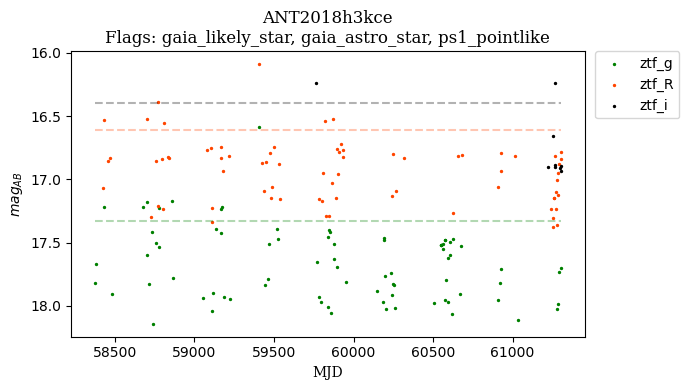

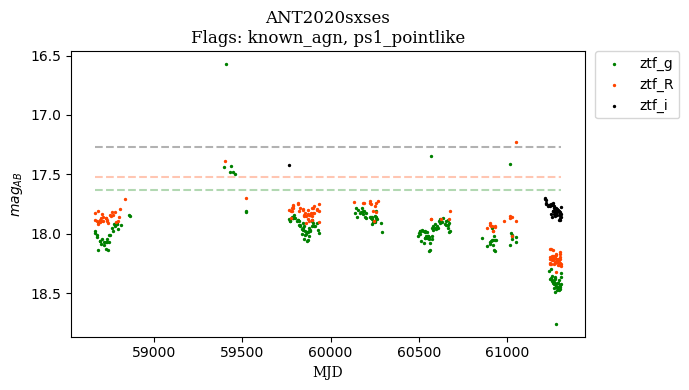

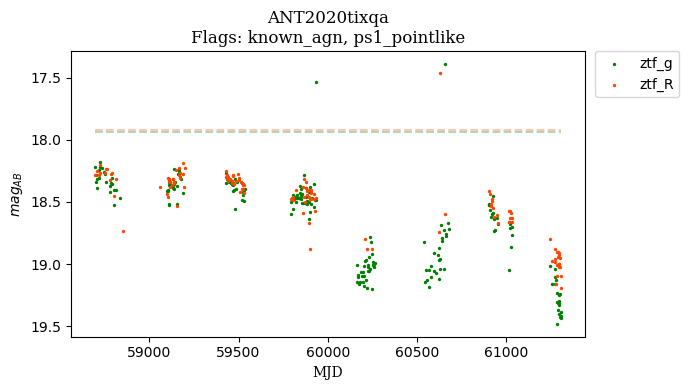

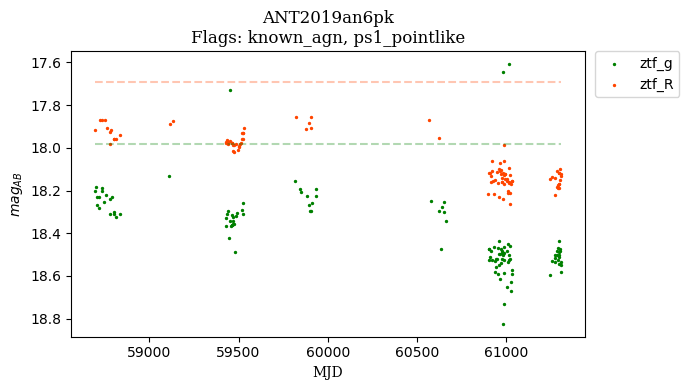

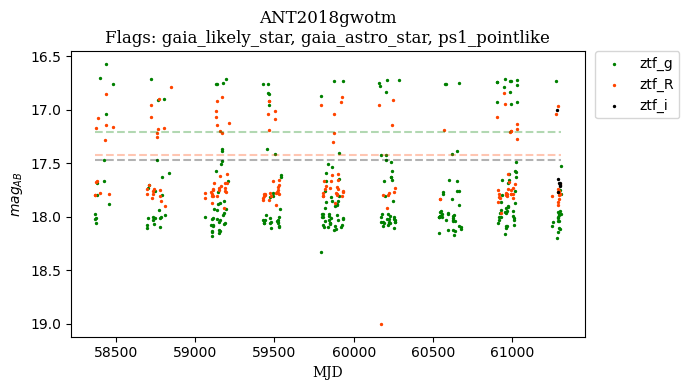

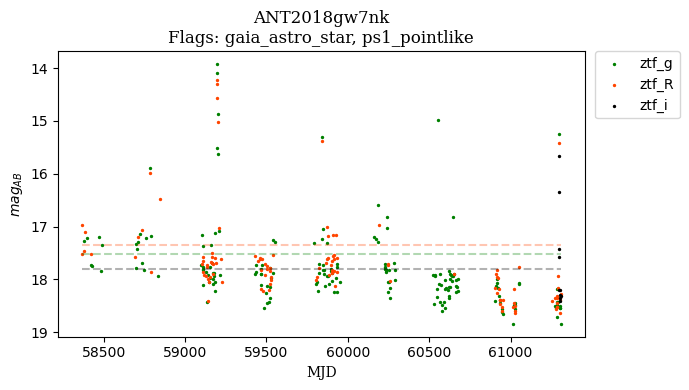

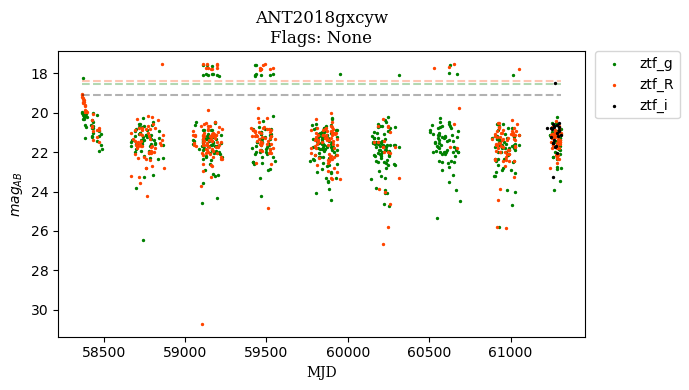

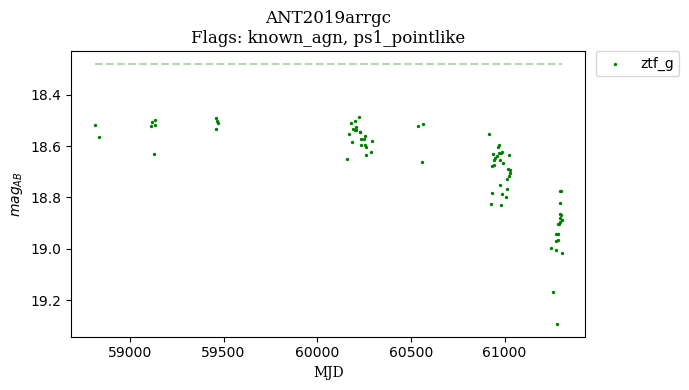

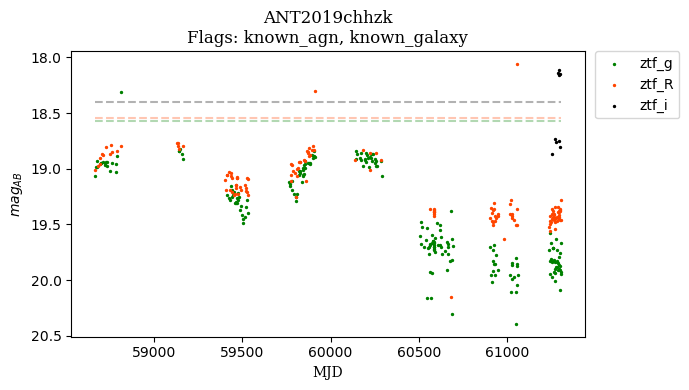

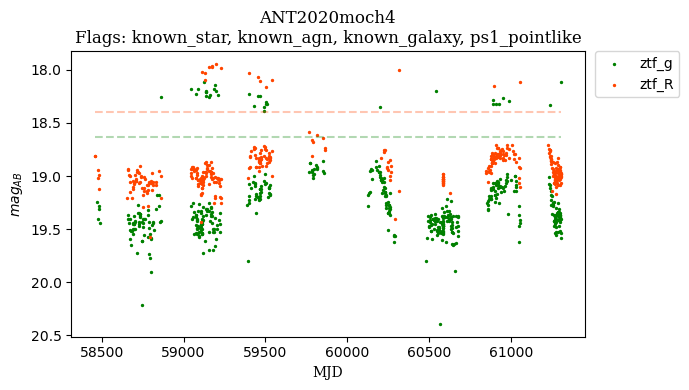

In [152]:
i = 0
j = 10
colors = {'ztf_g': 'green', 'ztf_R': 'orangered', 'ztf_i': 'black'}
for oid_id in list(dict.fromkeys(ids))[:j]:
    # if oid_id != 'ANT2020arszo':
        # continue
    fig, ax = plt.subplots(1,1, figsize=(7,4))
    # print(oid_id)
    locus = search.get_by_id(oid_id)
    lc = lightcurve(locus.alerts)
    title = oid_id
    flags_str = 'Flags: '
    for band in lc:
        if isinstance(lc[band], pd.DataFrame) == 0:
            continue
        ax.scatter(lc[band]['mjd'], lc[band]['mag'], s=2, c = colors[band], label=band)
        ax.hlines(y=np.average(lc[band]['temp_mag']), xmin = locus.properties['oldest_alert_observation_time'], xmax= locus.properties['newest_alert_observation_time'], 
                      colors = colors[band], alpha = 0.3, ls = '--')

    flags = catalog_check(locus)
    for flag in flags:
        if flags[flag] == True and len(flags_str) == 7:
            flags_str += flag
        elif flags[flag] == True:
            flags_str += ', ' + flag
            
    ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0.)
    ax.yaxis.set_inverted(True)
    if len(flags_str) > 7:
        plt.title(title + '\n' + flags_str, fontname = 'serif')
    else:
        plt.title(title + '\n' + flags_str + 'None', fontname = 'serif')
    plt.xlabel('MJD', fontname = 'serif')
    plt.ylabel('$mag_{AB}$', fontname = 'serif')
    plt.tight_layout()
    
    i+=1
j+=10
    # print(lc)

[]

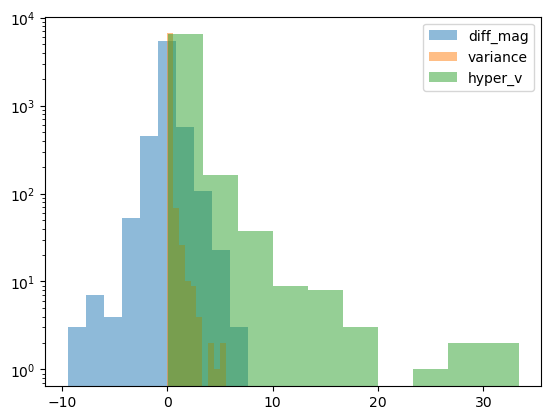

In [28]:
vp_f = 0 #variability parameters fail
hv_oids = {}
dm = []
var = []
hv = []
coeff = {'lsst': [], 'ztf': []}
for oid in oid_sample_61289:
    band_f = 0
    dm_temp = []
    var_temp = []
    hv_temp = []
    # oids_sample[oid] = catalog_check(oid_sample[oid])x
    for band in oid_sample_61289[oid]:
        if oid_sample_61289[oid][band] == 'locus' or band == 'flags':
            continue
        elif isinstance(oid_sample_61289[oid][band], dict) == 0:
            band_f += 1
            continue
        dm_temp.append(oid_sample_61289[oid][band]['diff_mag'])
        var_temp.append(oid_sample_61289[oid][band]['var'])
        hv_temp.append(oid_sample_61289[oid][band]['hyper_v'])
        if oid_sample_61289[oid][band]['var'] > 0.05:
            if band[0] == 'l':
                coeff['lsst'].append(abs(oid_sample_61289[oid][band]['diff_mag']/oid_sample_61289[oid][band]['var']))
            else:
                coeff['ztf'].append(abs(oid_sample_61289[oid][band]['diff_mag']/oid_sample_61289[oid][band]['var']))
    if max(hv_temp) >= 1:
            hv_oids[oid] = oid_sample_61289[oid]
    dm.append(max(dm_temp))
    var.append(max(var_temp))
    hv.append(max(hv_temp))
    
plt.hist(dm, alpha = 0.5, label = 'diff_mag')
plt.hist(var, alpha = 0.5, label = 'variance')
plt.hist(hv, alpha = 0.5, label = 'hyper_v')
plt.legend()
plt.semilogy()

In [135]:
thresh = pd.DataFrame(columns = ['threshold', 'count', 'pass/good qual%', 'pass/total%', 'trig alerts/sr', 'trig alerts/f_low', 'trig alerts/f_high'])
ts = np.arange(0.1, 1.1,0.1)
for t in ts:
    sr1 = 10*(np.pi*0.5/180)**2
    sr2 = 10*(np.pi*0.75/180)**2
    count = sum(abs(v) > t for v in dm)
    good_quality_p = float(100*count/len(hv))
    tot_p = float(100*count/checked_61289)
    density = count/(13*(np.pi**2)/18)
    thresh.loc[t-1] = [t, count, good_quality_p, tot_p, density, density*sr1, density*sr2]
    # print(f'note: these numbers come from using 75% of sky from observations on 09/05/26\nthreshold, % from good data, % from total query\n')
thresh  
# print(sr1*100/(13*(np.pi/18)**2), sr2*100/(13*(np.pi**2)/18))

,threshold,count,pass/good qual%,pass/total%,trig alerts/sr,trig alerts/f_low,trig alerts/f_high
-0.9,0.1,6644.0,98.736811,13.907437,932.092538,0.709829,1.597115
-0.8,0.2,5823.0,86.535889,12.188893,816.913734,0.622115,1.399760
-0.7,0.3,4367.0,64.898202,9.141147,612.650228,0.466560,1.049760
-0.6,0.4,3143.0,46.708278,6.579030,440.934203,0.335791,0.755529
-0.5,0.5,2373.0,35.265270,4.967241,332.910234,0.253526,0.570433
-0.4,0.6,1882.0,27.968495,3.939464,264.027417,0.201068,0.452404
-0.3,0.7,1579.0,23.465597,3.305214,221.519283,0.168697,0.379567
-0.2,0.8,1331.0,19.780056,2.786093,186.727148,0.142201,0.319952
-0.1,0.9,1167.0,17.342844,2.442802,163.719445,0.124679,0.280529
0.0,1.0,1028.0,15.277159,2.151843,144.219014,0.109829,0.247115


In [116]:
deg = 1.5
sr = (np.pi*deg/180)**2
sr

0.0006853891945200943

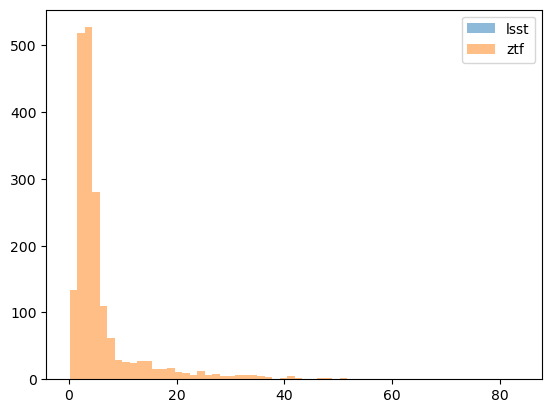

In [15]:
plt.hist(coeff['lsst'], bins = 50, label='lsst', alpha = 0.5)
plt.hist(coeff['ztf'], bins = 60, label='ztf', alpha = 0.5)
plt.legend()
# plt.semilogx()

In [208]:
print(len(coeff['lsst']), len(coeff['ztf']))

404 3373


In [16]:
print(np.median(coeff['lsst']), np.median(coeff['ztf']))

nan nan


/opt/anaconda3/lib/python3.13/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/opt/anaconda3/lib/python3.13/site-packages/numpy/_core/_methods.py:144: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [17]:
coeff['ztf']

[3.4677335198025556,
 1.9873600951546846,
 3.260829937766234,
 2.033098869492208,
 4.025551901429615,
 1.9903029711820317,
 4.700656783086779,
 12.947125560163615,
 21.312615892771586,
 4.184290673390906,
 3.745787270419571,
 3.018301803850234,
 1.9839525954356911,
 3.093816618056504,
 2.4979140065437337,
 2.2223926310299524,
 4.657384226348132,
 0.7510223769877272,
 2.0623020698803094,
 4.102109601992688,
 1.943117808614939,
 2.439628486280933,
 3.3934749583334,
 2.7486611206871148,
 2.5211545107879805,
 2.782933757721482,
 4.649621252182616,
 3.466762335439322,
 2.8036427049484627,
 3.640051412524556,
 1.984871322353379,
 3.908563818887465,
 2.629547354881821,
 2.336644345126517,
 5.211586463624424,
 4.625682483583742,
 3.5898236592541046,
 3.9311495864375177,
 14.233959953112512,
 1.2533618902522896,
 3.8046579195097436,
 2.605426166247937,
 nan,
 nan,
 3.0556690895659475,
 4.9316457394599365,
 4.2331584683676615,
 2.8530383023502526,
 3.4870892576051964,
 2.7046231648903363,
 2.135